RETAILMIND AI — DAY 3 MODEL TUNING

Dataset shape: (7043, 21)

First five rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...    

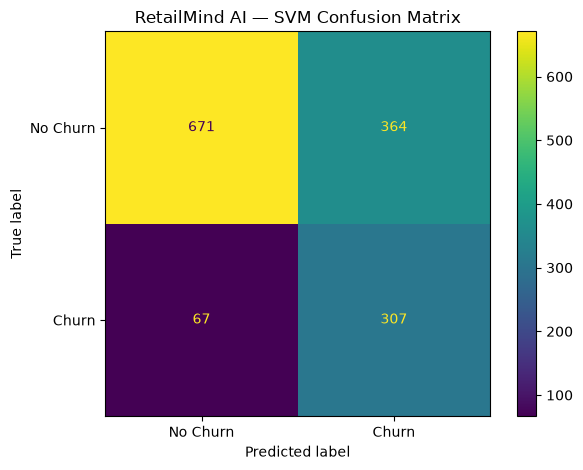


Generating learning curve...


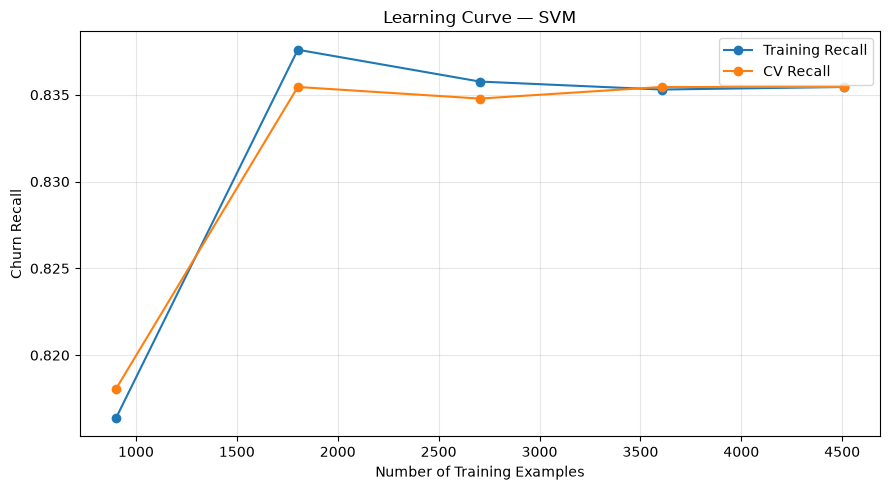


LEARNING CURVE INTERPRETATION:
- A large persistent training-CV gap may indicate high variance.
- Both curves low and close together may indicate high bias.
- Improving CV recall as sample size grows suggests more data may help.
- Curves that plateau suggest evaluating features or model complexity.

Champion saved to: ../models/churn_v3.joblib


In [2]:
# ============================================================
# RetailMind AI — Day 3
# Multi-Model Comparison, Hyperparameter Tuning & Bias-Variance
# Dataset: Telco Customer Churn
# ============================================================

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    learning_curve
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_PATH = "../data/Telco-Customer-Churn.csv"
TARGET = "Churn"
RANDOM_STATE = 42

os.makedirs("models", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD DATASET
# ------------------------------------------------------------

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Place the Telco Customer Churn CSV in your project "
        "directory or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("=" * 65)
print("RETAILMIND AI — DAY 3 MODEL TUNING")
print("=" * 65)
print("\nDataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found.")

# ------------------------------------------------------------
# 3. DATA CLEANING
# ------------------------------------------------------------

df = df.drop_duplicates().copy()

# customerID is an identifier, not a predictive feature.
df.drop(columns=["customerID"], errors="ignore", inplace=True)

# Convert TotalCharges to numeric; blank values become NaN.
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"], errors="coerce"
    )

# Normalize target labels.
df[TARGET] = df[TARGET].astype(str).str.strip()

df = df[df[TARGET].isin(["Yes", "No"])].copy()
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1}).astype(int)

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("\nCleaned dataset shape:", df.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nChurn rate:", round(y.mean(), 4))

# ------------------------------------------------------------
# 4. TRAIN-TEST SPLIT
# Keep the test set untouched during hyperparameter tuning.
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Identify numeric and categorical columns.
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# ------------------------------------------------------------
# 5. PREPROCESSING PIPELINE
# Imputation and encoding are fitted inside CV folds to prevent
# preprocessing leakage.
# ------------------------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# ------------------------------------------------------------
# 6. DEFINE MODELS AND HYPERPARAMETER GRIDS
# Use churn recall as the primary tuning metric.
# ------------------------------------------------------------

model_grids = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__C": [0.01, 0.1, 1, 10],
            "model__class_weight": [None, "balanced"]
        }
    },

    "Decision Tree": {
        "model": DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__max_depth": [3, 5, 10, None],
            "model__min_samples_split": [2, 10],
            "model__min_samples_leaf": [1, 5],
            "model__class_weight": [None, "balanced"]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "params": {
            "model__n_estimators": [100, 200],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 3],
            "model__class_weight": [None, "balanced"]
        }
    },

    "SVM": {
        "model": SVC(
            probability=True,
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear", "rbf"],
            "model__class_weight": [None, "balanced"]
        }
    }
}

# ------------------------------------------------------------
# 7. GRID SEARCH WITH STRATIFIED CROSS-VALIDATION
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

results = []
best_estimators = {}

for model_name, config in model_grids.items():

    print("\n" + "=" * 65)
    print("TUNING:", model_name)
    print("=" * 65)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", config["model"])
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        scoring="recall",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
        verbose=0
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    best_estimators[model_name] = best_model

    # Training metrics diagnose generalization.
    train_predictions = best_model.predict(X_train)
    validation_predictions = best_model.predict(X_test)

    train_recall = recall_score(
        y_train, train_predictions, zero_division=0
    )
    test_recall = recall_score(
        y_test, validation_predictions, zero_division=0
    )

    train_f1 = f1_score(
        y_train, train_predictions, zero_division=0
    )
    test_f1 = f1_score(
        y_test, validation_predictions, zero_division=0
    )

    test_precision = precision_score(
        y_test, validation_predictions, zero_division=0
    )
    test_accuracy = accuracy_score(
        y_test, validation_predictions
    )

    test_probabilities = best_model.predict_proba(X_test)[:, 1]
    test_auc = roc_auc_score(y_test, test_probabilities)

    results.append({
        "Model": model_name,
        "Best CV Recall": grid.best_score_,
        "Train Recall": train_recall,
        "Test Recall": test_recall,
        "Recall Gap": train_recall - grid.best_score_,
        "Train F1": train_f1,
        "Test F1": test_f1,
        "Test Precision": test_precision,
        "Test Accuracy": test_accuracy,
        "Test ROC-AUC": test_auc,
        "Best Parameters": grid.best_params_
    })

    print("Best CV Recall:", round(grid.best_score_, 4))
    print("Best Parameters:", grid.best_params_)
    print("Train Recall:", round(train_recall, 4))
    print("Test Recall:", round(test_recall, 4))
    print("Test F1:", round(test_f1, 4))
    print("Test ROC-AUC:", round(test_auc, 4))

# ------------------------------------------------------------
# 8. COMPARE MODELS
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    by="Best CV Recall", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("MODEL COMPARISON")
print("=" * 65)

display_columns = [
    "Model",
    "Best CV Recall",
    "Train Recall",
    "Test Recall",
    "Recall Gap",
    "Train F1",
    "Test F1",
    "Test Precision",
    "Test Accuracy",
    "Test ROC-AUC"
]

print(results_df[display_columns].round(4).to_string(index=False))

# ------------------------------------------------------------
# 9. BIAS-VARIANCE DIAGNOSIS
# A large train-CV gap suggests possible overfitting.
# Low training and CV scores suggest possible underfitting.
# These thresholds are heuristics, not definitive tests.
# ------------------------------------------------------------

def diagnose_bias_variance(row):
    train_score = row["Train Recall"]
    cv_score = row["Best CV Recall"]
    gap = train_score - cv_score

    if train_score < 0.55 and cv_score < 0.55:
        return "Possible high bias / underfitting"
    elif gap > 0.15:
        return "Possible high variance / overfitting"
    elif gap > 0.08:
        return "Moderate generalization gap"
    else:
        return "Relatively good generalization"

results_df["Bias-Variance Diagnosis"] = results_df.apply(
    diagnose_bias_variance, axis=1
)

print("\nBIAS-VARIANCE DIAGNOSIS:")
print(
    results_df[
        ["Model", "Train Recall", "Best CV Recall",
         "Recall Gap", "Bias-Variance Diagnosis"]
    ].round(4).to_string(index=False)
)

# ------------------------------------------------------------
# 10. SELECT CHAMPION USING CV RECALL
# Do not select the champion based on test-set performance.
# ------------------------------------------------------------

champion_name = results_df.iloc[0]["Model"]
champion = best_estimators[champion_name]

print("\n" + "=" * 65)
print("CHAMPION MODEL:", champion_name)
print("=" * 65)

# ------------------------------------------------------------
# 11. FINAL CHAMPION EVALUATION ON HELD-OUT TEST DATA
# ------------------------------------------------------------

y_pred = champion.predict(X_test)
y_prob = champion.predict_proba(X_test)[:, 1]

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(
    y_test, y_pred, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_test, y_pred, zero_division=0
), 4))
print("F1 Score:", round(f1_score(
    y_test, y_pred, zero_division=0
), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

# Confusion matrix.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"]
)
plt.title(f"RetailMind AI — {champion_name} Confusion Matrix")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. LEARNING CURVE
# Diagnose whether more training data might help.
# Uses the selected model and training partition only.
# ------------------------------------------------------------

print("\nGenerating learning curve...")

train_sizes, train_scores, cv_scores = learning_curve(
    estimator=champion,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.2, 1.0, 5),
    cv=cv,
    scoring="recall",
    n_jobs=-1,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_means = train_scores.mean(axis=1)
cv_means = cv_scores.mean(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_means, marker="o", label="Training Recall")
plt.plot(train_sizes, cv_means, marker="o", label="CV Recall")
plt.xlabel("Number of Training Examples")
plt.ylabel("Churn Recall")
plt.title(f"Learning Curve — {champion_name}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nLEARNING CURVE INTERPRETATION:")
print("- A large persistent training-CV gap may indicate high variance.")
print("- Both curves low and close together may indicate high bias.")
print("- Improving CV recall as sample size grows suggests more data may help.")
print("- Curves that plateau suggest evaluating features or model complexity.")

# ------------------------------------------------------------
# 13. SAVE CHAMPION MODEL
# ------------------------------------------------------------

MODEL_PATH = "../models/churn_v3.joblib"

joblib.dump(champion, MODEL_PATH)

print("\nChampion saved to:", MODEL_PATH)

# Save experiment metrics and hyperparameters.
report = {
    "project": "RetailMind AI",
    "increment": "Day 3",
    "champion_model": champion_name,
    "selection_metric": "5-fold stratified CV recall",
    "best_cv_recall": float(
        results_df.iloc[0]["Best CV Recall"]
    ),
    "best_parameters": best_estimators[
        champion_name
    ].named_steps["model"].get_params(),
    "test_metrics": {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(
            y_test, y_pred, zero_division=0
        )),
        "recall": float(recall_score(
            y_test, y_pred, zero_division=0
        )),
        "f1": float(f1_score(
            y_test, y_pred, zero_division=0
        )),
        "roc_auc": float(roc_auc_score(y_test, y_prob))
    }
}

# Convert NumPy values into JSON-compatible Python types.
def make_json_serializable(obj):
    if isinstance(obj, dict):
        return {
            str(k): make_json_serializable(v)
            for k, v in obj.items()
        }
    if isinstance(obj, (list, tuple)):
        return [make_json_serializable(v) for v in obj]
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, type):
        return str(obj)
    return obj

with open("reports/churn_v3_report.json", "w") as f:
    json.dump(make_json_serializable(report), f, indent=4)

results_df.drop(
    columns=["Best Parameters"], errors="ignore"
).to_csv("reports/model_comparison.csv", index=False)



In [3]:
import pandas as pd
